**Nama:** Sharren Elvaretta

**Kelas:** TI-3G

**NIM:** 244107020191

# Praktikum 1 Klasifikasi CNN dengan Dataset Lettuce


## Langkah 1 - Import Library

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, ConfusionMatrixDisplay

tf.keras.utils.set_random_seed(42)   # supaya hasil bisa diulang
print("TensorFlow:", tf.__version__)

TensorFlow: 2.21.0


## Langkah 2 Pra Pengolahan Data

### Langkah 2.1 Muat Dataset


In [2]:
import pandas as pd
from google.colab import files

uploaded = files.upload()                 # klik "Choose Files", pilih CSV dari file explorer
NAMA_FILE = list(uploaded.keys())[0]      # otomatis pakai nama file yang kamu pilih

KOLOM = ['id_tanaman', 'tanggal', 'suhu', 'kelembapan', 'tds', 'ph',
         'hst', 'suhu_f', 'kelembapan_frac']
df = pd.read_csv(NAMA_FILE, header=None, names=KOLOM)   # CSV tidak punya header
df['tanggal'] = pd.to_datetime(df['tanggal'], format='%m/%d/%Y')
df = df.sort_values(['id_tanaman', 'tanggal']).reset_index(drop=True)

print("Ukuran data:", df.shape)
df.head()

Saving lettuce_dataset_training_fix.csv to lettuce_dataset_training_fix.csv
Ukuran data: (2213, 9)


,id_tanaman,tanggal,suhu,kelembapan,tds,ph,hst,suhu_f,kelembapan_frac
0,22,2023-08-03,33.4,70,620,6.2,1,92.12,0.70
1,22,2023-08-04,33.5,63,800,6.5,2,92.30,0.63
2,22,2023-08-05,33.4,50,602,6.0,3,92.12,0.50
3,22,2023-08-06,33.4,50,721,6.0,4,92.12,0.50
4,22,2023-08-07,33.4,65,571,6.3,5,92.12,0.65


### Langkah 2.2 Mengenal Data


In [3]:
print("Jumlah tanaman :", df['id_tanaman'].nunique())
print("Nilai kosong   :", int(df.isna().sum().sum()))
print("Rentang tanggal:", df['tanggal'].min().date(), "s/d", df['tanggal'].max().date())
df[['suhu', 'kelembapan', 'tds', 'ph']].describe().round(2)

Jumlah tanaman : 49
Nilai kosong   : 0
Rentang tanggal: 2023-08-03 s/d 2023-09-19


,suhu,kelembapan,tds,ph
count,2213.00,2213.00,2213.00,2213.00
mean,27.07,64.76,598.87,6.40
std,5.00,9.04,116.84,0.23
min,18.00,50.00,400.00,6.00
25%,22.20,57.00,497.00,6.20
50%,29.80,65.00,593.00,6.40
75%,31.30,73.00,702.00,6.60
max,33.50,80.00,800.00,6.80


### Langkah 2.3 Pembuatan Label (Optimal vs. Tidak Optimal)


In [4]:
RENTANG = {
    'suhu':       (18, 25),
    'kelembapan': (50, 70),
    'tds':        (560, 840),
    'ph':         (5.5, 6.5),
}
FITUR = list(RENTANG.keys())
WINDOW = 10          # panjang jendela (hari)
AMBANG = 2.5         # rata-rata skor minimal agar dianggap Optimal

df['skor'] = sum(df[k].between(lo, hi).astype(int) for k, (lo, hi) in RENTANG.items())
print("Distribusi skor harian:")
print(df['skor'].value_counts().sort_index())

Distribusi skor harian:
skor
0     48
1    387
2    739
3    764
4    275
Name: count, dtype: int64


### Langkah 2.4 Bagi Data Training dan Testing


In [5]:
ids = np.sort(df['id_tanaman'].unique())
rng = np.random.RandomState(42)
id_test = rng.choice(ids, size=10, replace=False)

df_train = df[~df['id_tanaman'].isin(id_test)].copy()
df_test  = df[ df['id_tanaman'].isin(id_test)].copy()
print("Tanaman training:", df_train['id_tanaman'].nunique(),
      "| Tanaman testing:", df_test['id_tanaman'].nunique())

Tanaman training: 39 | Tanaman testing: 10


### Langkah 2.5 Normalisasi dan Pembuatan Jendela


In [6]:
scaler = StandardScaler().fit(df_train[FITUR])

def buat_window(data, window=WINDOW):
    X, y = [], []
    for _, g in data.groupby('id_tanaman'):
        g = g.sort_values('tanggal')
        fitur = scaler.transform(g[FITUR])
        skor = g['skor'].values
        for i in range(len(g) - window + 1):
            X.append(fitur[i:i + window])
            y.append(int(skor[i:i + window].mean() >= AMBANG))
    return np.array(X, dtype='float32'), np.array(y, dtype='float32')

X_train, y_train = buat_window(df_train)
X_test,  y_test  = buat_window(df_test)

print("X_train:", X_train.shape, "| y_train:", y_train.shape)
print("X_test :", X_test.shape,  "| y_test :", y_test.shape)
print("Proporsi kelas Optimal -> train: %.2f | test: %.2f" % (y_train.mean(), y_test.mean()))

X_train: (1410, 10, 4) | y_train: (1410,)
X_test : (362, 10, 4) | y_test : (362,)
Proporsi kelas Optimal -> train: 0.40 | test: 0.39


## Langkah 3 Pembuatan Model CNN

### Langkah 3.1 Inisiasi Model CNN

In [7]:
cnn = tf.keras.models.Sequential()

### Langkah 3.2 Layer Input dan Konvolusi 1


In [8]:
cnn.add(tf.keras.layers.Input(shape=(WINDOW, len(FITUR))))
cnn.add(tf.keras.layers.Conv1D(filters=32, kernel_size=3, padding='same', activation='relu'))

### Langkah 3.3 Layer Pooling 1

In [9]:
cnn.add(tf.keras.layers.MaxPool1D(pool_size=2, strides=2))

### Langkah 3.4 Layer Konvolusi 2 dan Pooling 2

In [10]:
cnn.add(tf.keras.layers.Conv1D(filters=32, kernel_size=3, padding='same', activation='relu'))
cnn.add(tf.keras.layers.MaxPool1D(pool_size=2, strides=2))

### Langkah 3.5 Flattening

In [11]:
cnn.add(tf.keras.layers.Flatten())

### Langkah 3.6 Fully Connected Layer 1 (Input)

In [12]:
cnn.add(tf.keras.layers.Dense(units=128, activation='relu'))

### Langkah 3.7 Fully Connected Layer 2 (Output)


In [13]:
cnn.add(tf.keras.layers.Dense(units=1, activation='sigmoid'))

### Langkah 3.8 Compile Model CNN


In [14]:
cnn.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
cnn.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d (Conv1D)                 │ (None, 10, 32)         │           416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d (MaxPooling1D)    │ (None, 5, 32)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_1 (Conv1D)               │ (None, 5, 32)          │         3,104 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_1 (MaxPooling1D)  │ (None, 2, 32)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │         8,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 11,969 (46.75 KB)

 Trainable params: 11,969 (46.75 KB)

 Non-trainable params: 0 (0.00 B)

## Langkah 4 Fit CNN


In [15]:
history = cnn.fit(x=X_train, y=y_train,
                  validation_data=(X_test, y_test),
                  epochs=25, batch_size=32)

Epoch 1/25
45/45 ━━━━━━━━━━━━━━━━━━━━ 2s 16ms/step - accuracy: 0.8461 - loss: 0.3337 - val_accuracy: 0.9448 - val_loss: 0.1934
Epoch 2/25
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.9645 - loss: 0.1321 - val_accuracy: 0.9503 - val_loss: 0.1570
Epoch 3/25
45/45 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.9667 - loss: 0.1146 - val_accuracy: 0.9475 - val_loss: 0.1361
Epoch 4/25
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.9695 - loss: 0.1012 - val_accuracy: 0.9475 - val_loss: 0.1226
Epoch 5/25
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.9688 - loss: 0.0920 - val_accuracy: 0.9475 - val_loss: 0.1146
Epoch 6/25
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.9695 - loss: 0.0834 - val_accuracy: 0.9503 - val_loss: 0.1105
Epoch 7/25
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.9730 - loss: 0.0746 - val_accuracy: 0.9558 - val_loss: 0.1077
Epoch 8/25
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9773 - loss: 0.0657 - val_accuracy: 0.9530 - val_loss

### Evaluasi Hasil Training

Akurasi testing: 0.9558 (95.58%)
Loss testing   : 0.1862


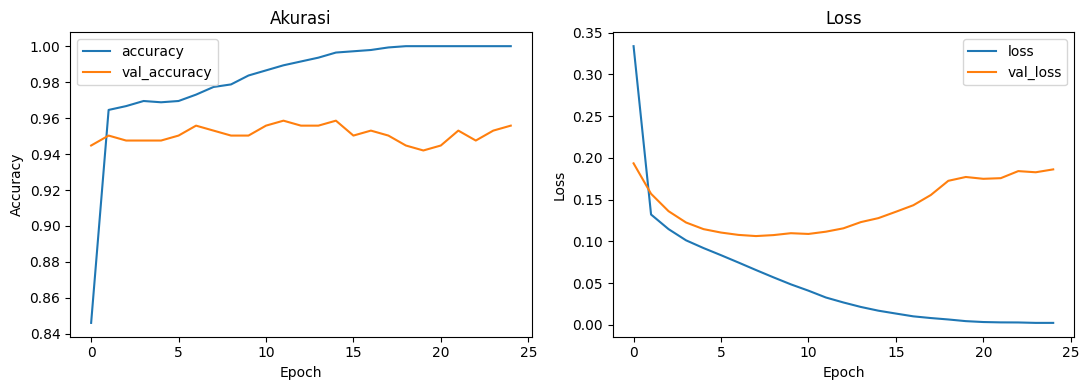

In [16]:
test_loss, test_acc = cnn.evaluate(X_test, y_test, verbose=0)
print("Akurasi testing: %.4f (%.2f%%)" % (test_acc, test_acc * 100))
print("Loss testing   : %.4f" % test_loss)

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(history.history['accuracy'], label='accuracy')
ax[0].plot(history.history['val_accuracy'], label='val_accuracy')
ax[0].set_xlabel('Epoch'); ax[0].set_ylabel('Accuracy'); ax[0].legend(); ax[0].set_title('Akurasi')
ax[1].plot(history.history['loss'], label='loss')
ax[1].plot(history.history['val_loss'], label='val_loss')
ax[1].set_xlabel('Epoch'); ax[1].set_ylabel('Loss'); ax[1].legend(); ax[1].set_title('Loss')
plt.tight_layout(); plt.show()

               precision    recall  f1-score   support

Tidak Optimal       0.96      0.96      0.96       222
      Optimal       0.94      0.94      0.94       140

     accuracy                           0.96       362
    macro avg       0.95      0.95      0.95       362
 weighted avg       0.96      0.96      0.96       362



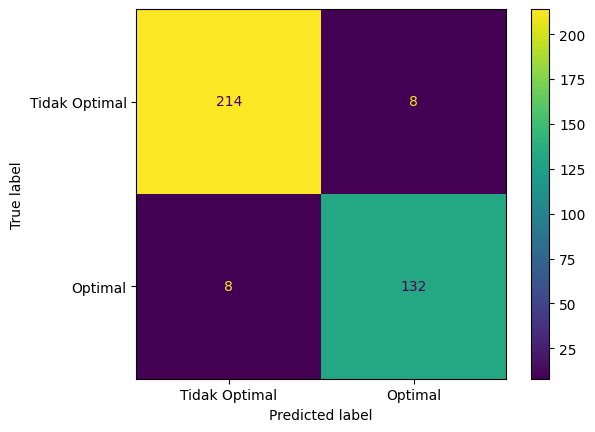

In [17]:
y_prob = cnn.predict(X_test, verbose=0).ravel()
y_pred = (y_prob >= 0.5).astype(int)

print(classification_report(y_test, y_pred, target_names=['Tidak Optimal', 'Optimal']))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred,
                                        display_labels=['Tidak Optimal', 'Optimal'])
plt.show()

## Langkah 5 Prediksi dengan 1 Sampel

### 5.1 Satu sampel dari data testing

In [18]:
nama_kelas = {0: 'Tidak Optimal', 1: 'Optimal'}

i = 0   # ubah indeks untuk mencoba sampel lain (0 s/d len(X_test)-1)
sampel = np.expand_dims(X_test[i], axis=0)     # bentuk (1, 10, 4)
result = cnn.predict(sampel, verbose=0)

print("Probabilitas Optimal:", round(float(result[0][0]), 4))
prediksi = nama_kelas[int(result[0][0] >= 0.5)]
print("Prediksi :", prediksi)
print("Label asli:", nama_kelas[int(y_test[i])])

Probabilitas Optimal: 0.0
Prediksi : Tidak Optimal
Label asli: Tidak Optimal


### 5.2 Data sensor baru (input manual)


In [19]:
data_baru = pd.DataFrame({
    'suhu':       [22.5, 23.0, 22.8, 21.9, 22.4, 23.1, 22.7, 22.2, 22.6, 23.0],
    'kelembapan': [62, 65, 60, 58, 63, 66, 61, 64, 59, 62],
    'tds':        [650, 700, 680, 720, 640, 690, 710, 660, 670, 700],
    'ph':         [6.2, 6.3, 6.1, 6.4, 6.2, 6.3, 6.0, 6.2, 6.1, 6.3],
})
assert len(data_baru) == WINDOW, f"Harus tepat {WINDOW} baris"

x_baru = scaler.transform(data_baru[FITUR]).astype('float32')
x_baru = np.expand_dims(x_baru, axis=0)
p = float(cnn.predict(x_baru, verbose=0)[0][0])

print("Probabilitas Optimal:", round(p, 4))
print("Prediksi:", nama_kelas[int(p >= 0.5)])

Probabilitas Optimal: 1.0
Prediksi: Optimal
